<a href="https://colab.research.google.com/github/premzea/APO-1/blob/main/Taller3Fraccionados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

####Datos

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
#CUANDO LO CORRA PREM
df = pd.read_excel('/content/drive/MyDrive/Pregrado_Icesi_Ingenieria_Bioquimica/2026-2/Modelos Predictivos/Taller 3/Base_de_datos.xlsx', sheet_name='DOE')
#print(df)

#CUANDO LO CORRA SILVIA #Nice, si
# df = pd.read_excel('Base_de_datos.xlsx', sheet_name='DOE')
print(df)

    Ensayo  X1  X2  X3  X4  ȠXyl  Ƞgalac  Ƞman  Ƞarab  Ƞhemi
0        1  -1  -1  -1  -1   5.0     0.0   7.0    0.0    1.3
1        2   1  -1  -1  -1   0.0     0.0   6.2    0.0    1.2
2        3  -1   1  -1  -1  28.2     0.0   8.6    0.0    1.7
3        4   1   1  -1  -1   0.0     0.0   7.4    0.0    1.4
4        5  -1  -1   1  -1   0.0     0.0   6.6   12.2    3.1
5        6   1  -1   1  -1   0.0     0.0   9.0    8.6    3.2
6        7  -1   1   1  -1   0.0     1.9   9.8   45.2    9.4
7        8   1   1   1  -1   0.0     2.8  10.2   49.8   10.4
8        9  -1  -1  -1   1   0.0     5.3   7.0   62.9   12.7
9       10   1  -1  -1   1   0.0     7.9   7.8   38.1    9.7
10      11  -1   1  -1   1   0.0    11.6  10.2   83.8   18.3
11      12   1   1  -1   1   0.0     8.3  13.5   82.7   17.8
12      13  -1  -1   1   1   0.0    35.7   9.0  100.0   29.3
13      14   1  -1   1   1   0.0    36.3   9.4  100.0   27.7
14      15  -1   1   1   1   0.0    51.0   8.6  100.0   42.1
15      16   1   1   1  

#### Ajuste Anova

In [4]:
  !pip install tabulate
  !pip install colorama

def Ajuste_ANOVA (design, var_name):
    # Ajustar un modelo de ANOVA factorial

    tabla_anova = sm.stats.anova_lm(modelo, typ=1)
    R2 = modelo.rsquared*100
    R2adj = modelo.rsquared_adj*100
    Df_Model = modelo.df_model
    p_value = modelo.f_pvalue
    resumen = modelo.summary2()

    # Crear una tabla HTML con fondo blanco, bordes negros y ancho automático de celdas
    tabla_html = f'''
    <table style="border-collapse: collapse; width: auto;">
      <tr style="background-color: grey;">
        <th style="border: 1px solid black; padding: 3px; color: black;">Estadístico</th>
        <th style="border: 1px solid black; padding: 3px; color: black;">Valor</th>
      </tr>
      <tr style="background-color: white;">
        <th style="border: 1px solid black; padding: 3px; text-align: right;color: black;">R<sup>2</sup> =</th>
        <td style="border: 1px solid black; padding: 3px; color: black;">{R2:.2f}%</td>
      </tr>
      <tr style="background-color: white;">
        <th style="border: 1px solid black; padding: 3px; text-align: right;color: black;">R<sub>ADJ</sub><sup>2</sup> =</th>
        <td style="border: 1px solid black; padding: 3px; color: black;">{R2adj:.2f}%</td>
      </tr>
      <tr style="background-color: white;">
        <th style="border: 1px solid black; padding: 3px; text-align: right;color: black;">Valor-p del modelo =</th>
        <td style="border: 1px solid black; padding: 3px; color: black;">{p_value:.6}</td>
      </tr>
      <tr style="background-color: white;">
        <th style="border: 1px solid black; padding: 3px; text-align: right;color: black;">GL del modelo =</th>
        <td style="border: 1px solid black; padding: 3px; background-color: white; color: black;">{Df_Model}</td>
      </tr>
    </table>
    '''

    # Mostrar la tabla HTML de la calidad del modelo y el ANOVA
    from IPython.display import display, HTML
    display(HTML(tabla_html))
    print(tabla_anova)
    print()

    # Extraer el valor p máximo
    nombre_efecto_menor_p = tabla_anova['PR(>F)'].idxmax()
    mayor_valor_p = tabla_anova['PR(>F)'].max()

    # Crear una tabla HTML para el menor efecto con fondo blanco, bordes negros y ancho automático de celdas
    tabla_html = f'''
    <table style="border-collapse: collapse; width: auto;; margin-left: 255px;">
      <tr style="background-color: white;">
        <th style="border: 1px solid black; padding: 5px; text-align: right;color: black;">Efecto menos significativo:</th>
        <td style="border: 1px solid black; padding: 5px; color: black;">{nombre_efecto_menor_p}</td>
      </tr>
      <tr style="background-color: white;">
        <th style="border: 1px solid black; padding: 5px; text-align: right;color: black;">Valor p:</th>
        <td style="border: 1px solid black; padding: 5px; background-color: white; color: black;">{mayor_valor_p:.6}</td>
      </tr>
    </table>
    '''
    # Mostrar la tabla HTML para el menor efecto
    display(HTML(tabla_html))
    print()

    # Extraer los coeficientes del modelo
    coeficientes = modelo.params
    print(coeficientes)
    print()

    # Crear la ecuación del modelo
    ecuacion_modelo = ""

    # Obtener los nombres de las variables predictoras
    variables_predictoras = [nombre for nombre in coeficientes.index]

    # Agregar los términos de las variables predictoras y sus coeficientes
    for variable in variables_predictoras:
        coeficiente = coeficientes.get(variable, 0)
        ecuacion_modelo += " + {:.4f} * {}".format(coeficiente, variable)

    # Eliminar el primer '+' y agregar "Y = " al principio
    ecuacion_modelo = var_name + "= " + ecuacion_modelo[2:]

    # Imprimir la ecuación del modelo
    print("Ecuación del modelo:")
    print(ecuacion_modelo)

#### Falta de Ajuste de Datos y Analisis de Curvatura

In [5]:
def Analizar_Curvatura_y_faltaDeAjuste (design, factors, modelo, var_name='Y'):
    """
    Analiza un diseño experimental factorial (2^k o 3^k), Central Composite Design (CCD) o Box-Behnken.
    Calcula ANOVA, falta de ajuste y curvatura si aplica.

    Parámetros:
    design: DataFrame con los factores y la respuesta 'Y'.
    factors: Lista de nombres de los factores en el diseño.
    """
    # Separar puntos factoriales y centrales
    factors = list(design.columns[:len(factors)])  # Última columna es la respuesta 'Y' -> Lo cambie a menos 5 porque tenemos 5 variables de respuesta
    factorial_data = design[(design[factors] != 0).any(axis=1)]
    central_data = design[(design[factors] == 0).all(axis=1)]

    # Calcular medias
    Y_f = factorial_data[var_name].mean()
    Y_c = central_data[var_name].mean() if not central_data.empty else np.nan
    n_f = len(factorial_data)
    n_c = len(central_data)

    # Recalcular la ANOVA del modelo ajustado
    tabla_anova = sm.stats.anova_lm(modelo, typ=2)

    # Calcular error puro si hay réplicas en algún punto
    error_puro = design.groupby(factors)[var_name].agg(['mean', 'count', 'var'])
    error_puro = error_puro[error_puro['count'] > 1]  # Solo puntos con réplicas
    SS_error_puro = (error_puro['var'] * (error_puro['count'] - 1)).sum()
    df_error_puro = (error_puro['count'] - 1).sum()

    # Calcular falta de ajuste si hay datos suficientes
    SS_error_total = tabla_anova.loc['Residual', 'sum_sq']
    df_error_total = tabla_anova.loc['Residual', 'df']
    SS_lack_of_fit = SS_error_total - SS_error_puro if df_error_puro > 0 else np.nan
    df_lack_of_fit = df_error_total - df_error_puro if df_error_puro > 0 else np.nan

    MS_lack_of_fit = SS_lack_of_fit / df_lack_of_fit if df_lack_of_fit > 0 else np.nan
    MS_error_puro = SS_error_puro / df_error_puro if df_error_puro > 0 else np.nan
    F_lack_of_fit = MS_lack_of_fit / MS_error_puro if MS_error_puro > 0 else np.nan
    p_value_lack_of_fit = 1 - f.cdf(F_lack_of_fit, df_lack_of_fit, df_error_puro) if MS_error_puro > 0 else np.nan
    print(f"Error Puro: {df_error_puro}, df_lack_of_fit: {df_lack_of_fit}, MS_error_puro: {MS_error_puro}, p_value_lack_of_fit: {p_value_lack_of_fit}")

    # Calcular curvatura solo si hay puntos centrales
    if not central_data.empty:
        print('Central Data not empty')
        SS_curvatura = n_c * n_f * ((Y_c - Y_f) ** 2) / (n_c + n_f)
        MS_curvatura = SS_curvatura / 1
        MS_error = SS_error_total / df_error_total
        F_curvatura = MS_curvatura / MS_error
        p_value_curvatura = 1 - f.cdf(F_curvatura, 1, df_error_total)
    else:
        SS_curvatura = MS_curvatura = F_curvatura = p_value_curvatura = np.nan
        print('Central Data empty')

    # Mostrar resultados

    print("\n--- Falta de ajuste ---")
    print(f"Suma de Cuadrados de Falta de Ajuste: {SS_lack_of_fit}")
    print(f"Grados de libertad de Falta de Ajuste: {df_lack_of_fit}")
    print(f"F-valor para Falta de Ajuste: {F_lack_of_fit}")
    print(f"\033[1m p-valor para Falta de Ajuste: {p_value_lack_of_fit} \033[0m")

    print("\n--- Curvatura (solo si hay puntos centrales) ---")
    print(f"Suma de Cuadrados de Curvatura: {SS_curvatura}")
    print(f"F-valor para Curvatura: {F_curvatura}")
    print(f"\033[1m p-valor para Curvatura: {p_value_curvatura} \033[0m")


### Nuestro diseño fraccionado

In [7]:
%pip install -q \
    "numpy==2.2.6" \
    "numba==0.65.1" \
    doepy3 pyDOE3 pandas statsmodels

In [8]:
from doepy3 import build
import pandas as pd
import numpy as np
import scipy.stats as f
import statsmodels.api as sm
from statsmodels.formula.api import ols
import matplotlib.pyplot as plt

import warnings
warnings.simplefilter("ignore", UserWarning)

In [9]:
def aliasFinder(design):
#importante: agregar plan de accion si se ejecuta cuando ya existe una columna alias
  alias = []
  for i in design['Yates']:
    string = ''
    for j in list(factors.keys()):
      if j not in i:
        string += j
    alias.append(string)
  design['Alias'] = alias
  dicAlias = design.set_index('Yates')['Alias'].to_dict()
  return dicAlias

def yatesNoter(design):
#importante: agregar plan de accion si se ejecuta cuando ya existe una columna yates
    yates = []
    for i in design.index:
        string = ''
        for j in list(factors.keys()):
            if design.loc[i, str(j)] == 1:
                string += str(j)
        yates.append(string)
    design['Yates'] = yates

In [10]:
# A: Proporcion Liquido-Solido
# B: Concentracion de Acido Sulfurico
# C: Tiempo de Reacción
# D: Temperatura

factors = {
    'A': [-1, 1],
    'B': [-1, 1],
    'C': [-1, 1],
    'D': [-1, 1],}

design = build.full_fact(factors)


# Crear un nuevo DataFrame para la fracción principal del diseño, con las filas donde la columna 'ABCD' es igual a 1
# Agregar una nueva columna 'ABCD' que contenga la multiplicación de las 4 columnas A, B, C y D
design['ABCD'] = design['A'] * design['B'] * design['C'] * design['D']

yatesNoter(design)
aliases = aliasFinder(design) #solo funciona para p=1 #asi queda cool porque si necesitass un alias puedes solo buscarlo en el dic. Y esta para todos.

PuntosCentrales = 3

Factores = len(factors)

central_points = pd.DataFrame(
    [[0] * (Factores + 3)] * PuntosCentrales, #mas uno porque producto de puntos centrales es igual a cero, y lo mismo para el yates y alias
    columns=design.columns
)

design = pd.concat(
    [design, central_points],
    ignore_index=True
)

res = ['ȠXyl', 'Ƞarab', 'Ƞman', 'Ƞhemi', 'Ƞgalac']

for i in res:
  if len(df[i]) != len(design):
      raise ValueError(
          f"El diseño tiene {len(design)} corridas, "
          f"pero ingresaste {len(df[i])} valores de Y."
      )
  else:
    design[i] = df[i]


design = design[design['ABCD'] != -1]

# Imprimir el nuevo DataFrame
print(design)

      A    B    C    D  ABCD Yates Alias  ȠXyl  Ƞarab  Ƞman  Ƞhemi  Ƞgalac
0  -1.0 -1.0 -1.0 -1.0   1.0        ABCD   5.0    0.0   7.0    1.3     0.0
3   1.0  1.0 -1.0 -1.0   1.0    AB    CD   0.0    0.0   7.4    1.4     0.0
5   1.0 -1.0  1.0 -1.0   1.0    AC    BD   0.0    8.6   9.0    3.2     0.0
6  -1.0  1.0  1.0 -1.0   1.0    BC    AD   0.0   45.2   9.8    9.4     1.9
9   1.0 -1.0 -1.0  1.0   1.0    AD    BC   0.0   38.1   7.8    9.7     7.9
10 -1.0  1.0 -1.0  1.0   1.0    BD    AC   0.0   83.8  10.2   18.3    11.6
12 -1.0 -1.0  1.0  1.0   1.0    CD    AB   0.0  100.0   9.0   29.3    35.7
15  1.0  1.0  1.0  1.0   1.0  ABCD        14.4  100.0  18.0   35.4    38.7
16  0.0  0.0  0.0  0.0   0.0     0     0   0.0   98.0  18.9   21.3     8.7
17  0.0  0.0  0.0  0.0   0.0     0     0   0.0   79.7  20.5   21.1    16.9
18  0.0  0.0  0.0  0.0   0.0     0     0   0.0   73.6  21.7   18.7    10.9


/usr/local/lib/python3.13/dist-packages/doepy3/doe_functions.py:28: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df.iloc[i][j] = r[j][int(df.iloc[i][j])]


##### Agregar Columnas de Interaccion Doble a DF

In [11]:
def createInteractionColumns(design):
  #aqui se le agregan los Alias. Por alguna razon solo se agregan los de las interacciones dobles, todavia no entiendo muy bien porque. Skill Issue. I've always known. Y no tienen que ser los alias, no? podria ser solo las dobles.
  newColumns = []
  for i in design['Alias'].iloc[:-PuntosCentrales]:
    if len(i) == 2:
      design[i[0] + i[1]] = design[i[0]] * design[i[1]]
      newColumns.append(i[0] + i[1])
  return newColumns

newColumns = createInteractionColumns(design)

In [12]:
print(design)

      A    B    C    D  ABCD Yates Alias  ȠXyl  Ƞarab  Ƞman  Ƞhemi  Ƞgalac  \
0  -1.0 -1.0 -1.0 -1.0   1.0        ABCD   5.0    0.0   7.0    1.3     0.0   
3   1.0  1.0 -1.0 -1.0   1.0    AB    CD   0.0    0.0   7.4    1.4     0.0   
5   1.0 -1.0  1.0 -1.0   1.0    AC    BD   0.0    8.6   9.0    3.2     0.0   
6  -1.0  1.0  1.0 -1.0   1.0    BC    AD   0.0   45.2   9.8    9.4     1.9   
9   1.0 -1.0 -1.0  1.0   1.0    AD    BC   0.0   38.1   7.8    9.7     7.9   
10 -1.0  1.0 -1.0  1.0   1.0    BD    AC   0.0   83.8  10.2   18.3    11.6   
12 -1.0 -1.0  1.0  1.0   1.0    CD    AB   0.0  100.0   9.0   29.3    35.7   
15  1.0  1.0  1.0  1.0   1.0  ABCD        14.4  100.0  18.0   35.4    38.7   
16  0.0  0.0  0.0  0.0   0.0     0     0   0.0   98.0  18.9   21.3     8.7   
17  0.0  0.0  0.0  0.0   0.0     0     0   0.0   79.7  20.5   21.1    16.9   
18  0.0  0.0  0.0  0.0   0.0     0     0   0.0   73.6  21.7   18.7    10.9   

     CD   BD   AD   BC   AC   AB  
0   1.0  1.0  1.0  1.0  1.0 

#### Calculo Tamaño efectos (no lo use) y gráficas de efectos principales (esas si)
Yo al reves. Aun asi, muestran lo mismo, no?


In [13]:
def calcEfectos(varRes):
  efectos = {}

  for termino in np.concat([newColumns, list(factors.keys())]):

      media_alta = design.loc[design[termino] == 1, varRes].mean()
      media_baja = design.loc[design[termino] == -1, varRes].mean()

      efecto = media_alta - media_baja

      efectos[termino] = efecto


  print("EFECTOS ORIGINALES")
  print("------------------")

  for termino, efecto in efectos.items():
      print(f"{termino}: {efecto:.2f}")


  # ============================================================
  # 2. EFECTOS ABSOLUTOS ORDENADOS DE MENOR A MAYOR
  # ============================================================

  efectos_absolutos = {
      termino: abs(efecto)
      for termino, efecto in efectos.items()
  }

  efectos_ordenados = sorted(
      efectos_absolutos.items(),
      key=lambda x: x[1]
  )

  print("\nEFECTOS ABSOLUTOS ORDENADOS")
  print("---------------------------")

  for termino, efecto_abs in efectos_ordenados:
      print(f"{termino}: {efecto_abs:.2f}")

##### Arabinosa

In [14]:
calcEfectos('Ƞarab')

EFECTOS ORIGINALES
------------------
CD: 6.08
BD: 2.27
AD: -2.27
BC: -2.27
AC: 2.27
AB: 6.08
A: -20.58
B: 20.58
C: 32.98
D: 67.02

EFECTOS ABSOLUTOS ORDENADOS
---------------------------
BD: 2.27
AD: 2.27
BC: 2.27
AC: 2.27
CD: 6.08
AB: 6.08
A: 20.58
B: 20.58
C: 32.98
D: 67.02


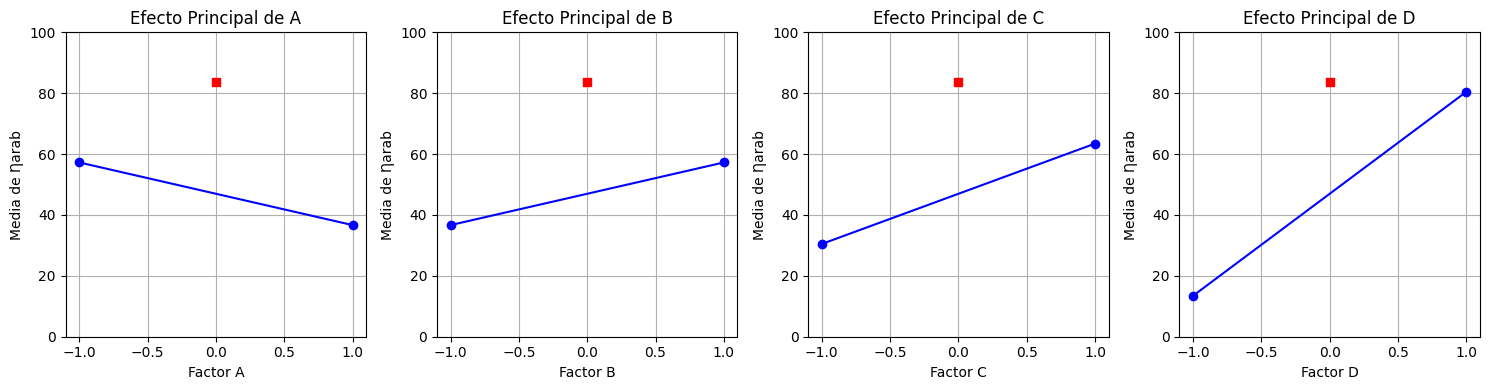

In [15]:
def plot_main_effects(design, factors): # utilizar solo para factoriales 2^k con o sin puntos centrales
    fig, axes = plt.subplots(1, len(factors), figsize=(15, 4))
    y_min, y_max = design['Ƞarab'].min(), design['Ƞarab'].max()

    for i, factor in enumerate(factors):
        # Calcular las medias para los niveles bajos (-1), altos (+1) y el punto central (0)
        means = design.groupby(factor)['Ƞarab'].mean()

        # Filtrar niveles factoriales (-1 y 1)
        factor_levels = means.loc[[-1, 1]]

        # Graficar la línea de efecto principal conectando solo -1 y 1
        axes[i].plot(factor_levels.index, factor_levels.values, marker='o', linestyle='-', color='b')

        # Agregar el punto central (0) sin conectar
        if 0 in means.index:
            axes[i].scatter(0, means.loc[0], color='r', marker='s', zorder=3)

        axes[i].set_title(f'Efecto Principal de {factor}')
        axes[i].set_xlabel(f'Factor {factor}')
        axes[i].set_ylabel('Media de Ƞarab')
        axes[i].set_ylim(y_min, y_max)
        axes[i].grid()

    plt.tight_layout()
    plt.show()

# Graficar efectos principales
plot_main_effects(design, ['A', 'B', 'C', 'D'])

##### Galactosa

In [16]:
calcEfectos('Ƞgalac')

EFECTOS ORIGINALES
------------------
CD: 13.25
BD: 1.20
AD: 0.30
BC: 0.30
AC: 1.20
AB: 13.25
A: -0.65
B: 2.15
C: 14.20
D: 23.00

EFECTOS ABSOLUTOS ORDENADOS
---------------------------
AD: 0.30
BC: 0.30
A: 0.65
BD: 1.20
AC: 1.20
B: 2.15
CD: 13.25
AB: 13.25
C: 14.20
D: 23.00


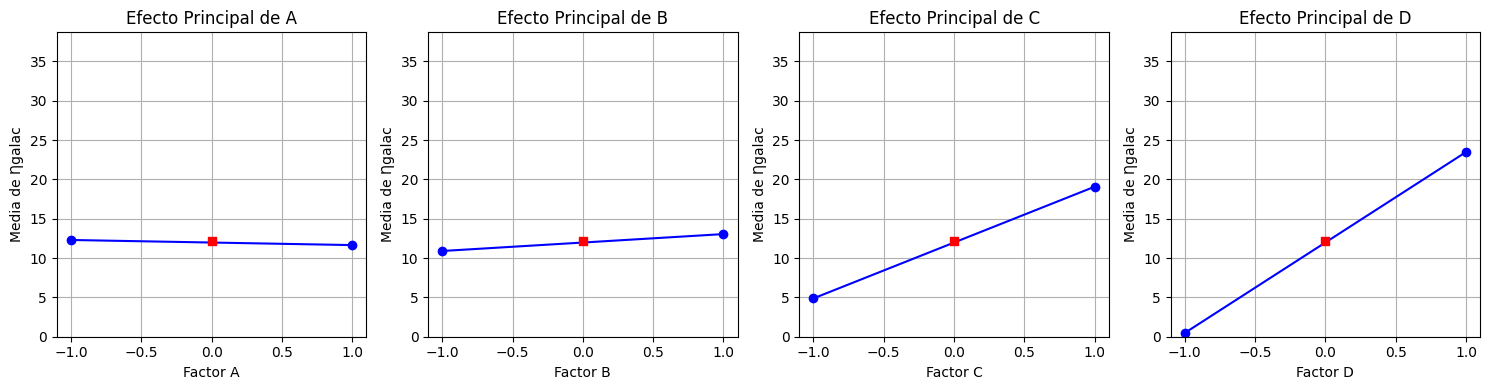

In [17]:
def plot_main_effects(design, factors): # utilizar solo para factoriales 2^k con o sin puntos centrales
    fig, axes = plt.subplots(1, len(factors), figsize=(15, 4))
    y_min, y_max = design['Ƞgalac'].min(), design['Ƞgalac'].max()

    for i, factor in enumerate(factors):
        # Calcular las medias para los niveles bajos (-1), altos (+1) y el punto central (0)
        means = design.groupby(factor)['Ƞgalac'].mean()

        # Filtrar niveles factoriales (-1 y 1)
        factor_levels = means.loc[[-1, 1]]

        # Graficar la línea de efecto principal conectando solo -1 y 1
        axes[i].plot(factor_levels.index, factor_levels.values, marker='o', linestyle='-', color='b')

        # Agregar el punto central (0) sin conectar
        if 0 in means.index:
            axes[i].scatter(0, means.loc[0], color='r', marker='s', zorder=3)

        axes[i].set_title(f'Efecto Principal de {factor}')
        axes[i].set_xlabel(f'Factor {factor}')
        axes[i].set_ylabel('Media de Ƞgalac')
        axes[i].set_ylim(y_min, y_max)
        axes[i].grid()

    plt.tight_layout()
    plt.show()

# Graficar efectos principales
plot_main_effects(design, ['A', 'B', 'C', 'D'])

##### Hemicelulosa

In [18]:
calcEfectos('Ƞhemi')

EFECTOS ORIGINALES
------------------
CD: 6.70
BD: 2.10
AD: 0.90
BC: 0.90
AC: 2.10
AB: 6.70
A: -2.15
B: 5.25
C: 11.65
D: 19.35

EFECTOS ABSOLUTOS ORDENADOS
---------------------------
AD: 0.90
BC: 0.90
BD: 2.10
AC: 2.10
A: 2.15
B: 5.25
CD: 6.70
AB: 6.70
C: 11.65
D: 19.35


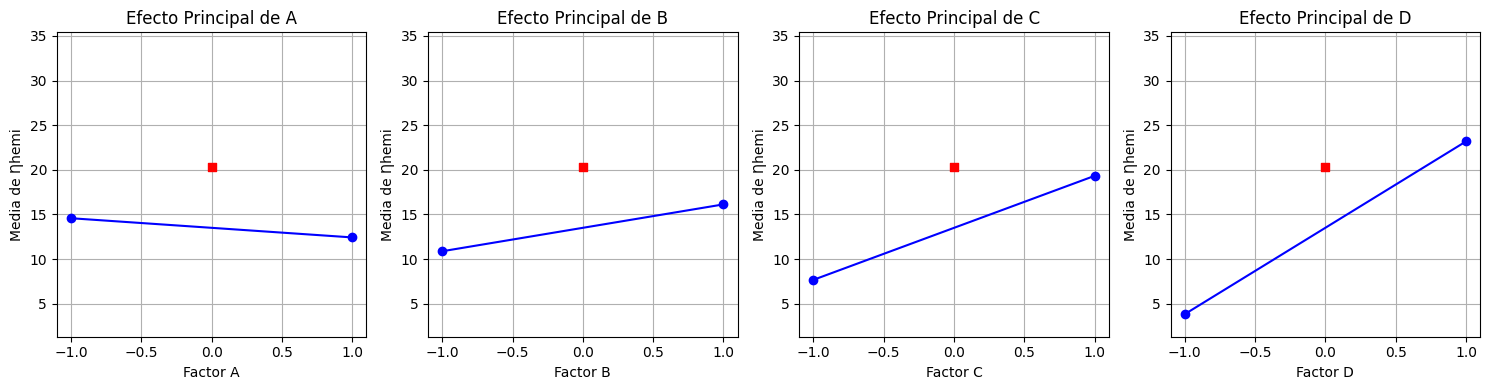

In [19]:
def plot_main_effects(design, factors): # utilizar solo para factoriales 2^k con o sin puntos centrales
    fig, axes = plt.subplots(1, len(factors), figsize=(15, 4))
    y_min, y_max = design['Ƞhemi'].min(), design['Ƞhemi'].max()

    for i, factor in enumerate(factors):
        # Calcular las medias para los niveles bajos (-1), altos (+1) y el punto central (0)
        means = design.groupby(factor)['Ƞhemi'].mean()

        # Filtrar niveles factoriales (-1 y 1)
        factor_levels = means.loc[[-1, 1]]

        # Graficar la línea de efecto principal conectando solo -1 y 1
        axes[i].plot(factor_levels.index, factor_levels.values, marker='o', linestyle='-', color='b')

        # Agregar el punto central (0) sin conectar
        if 0 in means.index:
            axes[i].scatter(0, means.loc[0], color='r', marker='s', zorder=3)

        axes[i].set_title(f'Efecto Principal de {factor}')
        axes[i].set_xlabel(f'Factor {factor}')
        axes[i].set_ylabel('Media de Ƞhemi')
        axes[i].set_ylim(y_min, y_max)
        axes[i].grid()

    plt.tight_layout()
    plt.show()

# Graficar efectos principales
plot_main_effects(design, ['A', 'B', 'C', 'D'])

##### Manosa

In [20]:
calcEfectos('Ƞman')

EFECTOS ORIGINALES
------------------
CD: 1.15
BD: 2.55
AD: 1.75
BC: 1.75
AC: 2.55
AB: 1.15
A: 1.55
B: 3.15
C: 3.35
D: 2.95

EFECTOS ABSOLUTOS ORDENADOS
---------------------------
CD: 1.15
AB: 1.15
A: 1.55
AD: 1.75
BC: 1.75
BD: 2.55
AC: 2.55
D: 2.95
B: 3.15
C: 3.35


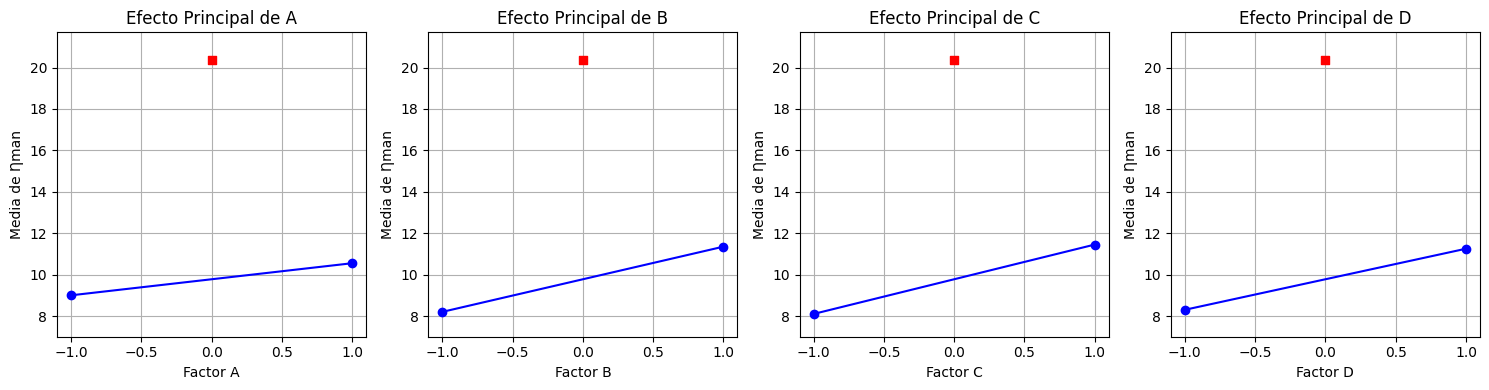

In [21]:
def plot_main_effects(design, factors): # utilizar solo para factoriales 2^k con o sin puntos centrales
    fig, axes = plt.subplots(1, len(factors), figsize=(15, 4))
    y_min, y_max = design['Ƞman'].min(), design['Ƞman'].max()

    for i, factor in enumerate(factors):
        # Calcular las medias para los niveles bajos (-1), altos (+1) y el punto central (0)
        means = design.groupby(factor)['Ƞman'].mean()

        # Filtrar niveles factoriales (-1 y 1)
        factor_levels = means.loc[[-1, 1]]

        # Graficar la línea de efecto principal conectando solo -1 y 1
        axes[i].plot(factor_levels.index, factor_levels.values, marker='o', linestyle='-', color='b')

        # Agregar el punto central (0) sin conectar
        if 0 in means.index:
            axes[i].scatter(0, means.loc[0], color='r', marker='s', zorder=3)

        axes[i].set_title(f'Efecto Principal de {factor}')
        axes[i].set_xlabel(f'Factor {factor}')
        axes[i].set_ylabel('Media de Ƞman')
        axes[i].set_ylim(y_min, y_max)
        axes[i].grid()

    plt.tight_layout()
    plt.show()

# Graficar efectos principales
plot_main_effects(design, ['A', 'B', 'C', 'D'])

##### Xilosa

In [22]:
calcEfectos('ȠXyl')

EFECTOS ORIGINALES
------------------
CD: 4.85
BD: 4.85
AD: 4.85
BC: 4.85
AC: 4.85
AB: 4.85
A: 2.35
B: 2.35
C: 2.35
D: 2.35

EFECTOS ABSOLUTOS ORDENADOS
---------------------------
A: 2.35
B: 2.35
C: 2.35
D: 2.35
CD: 4.85
BD: 4.85
AD: 4.85
BC: 4.85
AC: 4.85
AB: 4.85


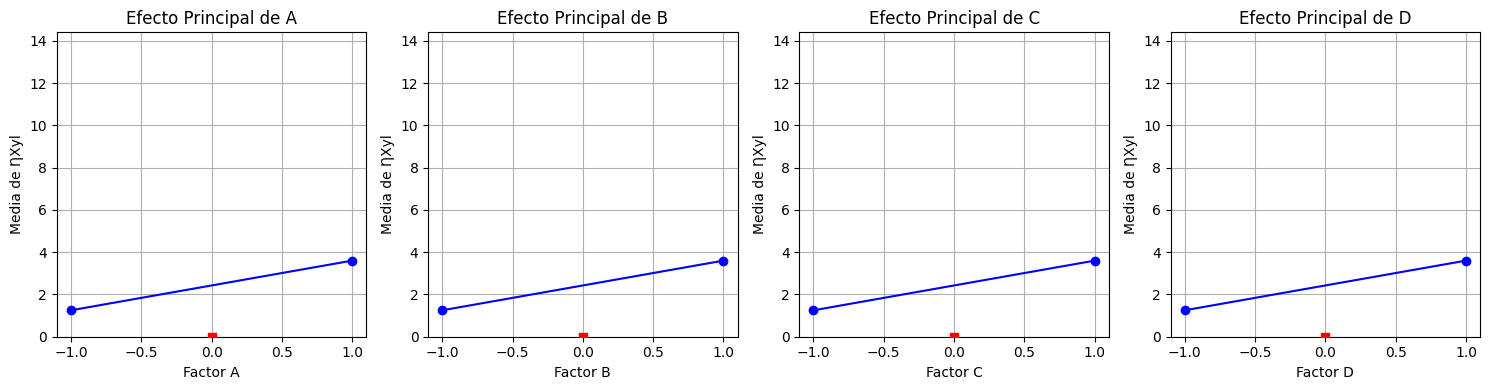

In [23]:
def plot_main_effects(design, factors): # utilizar solo para factoriales 2^k con o sin puntos centrales
    fig, axes = plt.subplots(1, len(factors), figsize=(15, 4))
    y_min, y_max = design['ȠXyl'].min(), design['ȠXyl'].max()

    for i, factor in enumerate(factors):
        # Calcular las medias para los niveles bajos (-1), altos (+1) y el punto central (0)
        means = design.groupby(factor)['ȠXyl'].mean()

        # Filtrar niveles factoriales (-1 y 1)
        factor_levels = means.loc[[-1, 1]]

        # Graficar la línea de efecto principal conectando solo -1 y 1
        axes[i].plot(factor_levels.index, factor_levels.values, marker='o', linestyle='-', color='b')

        # Agregar el punto central (0) sin conectar
        if 0 in means.index:
            axes[i].scatter(0, means.loc[0], color='r', marker='s', zorder=3)

        axes[i].set_title(f'Efecto Principal de {factor}')
        axes[i].set_xlabel(f'Factor {factor}')
        axes[i].set_ylabel('Media de ȠXyl')
        axes[i].set_ylim(y_min, y_max)
        axes[i].grid()

    plt.tight_layout()
    plt.show()

# Graficar efectos principales
plot_main_effects(design, ['A', 'B', 'C', 'D'])

#### Modelos

In [24]:
print(design)

      A    B    C    D  ABCD Yates Alias  ȠXyl  Ƞarab  Ƞman  Ƞhemi  Ƞgalac  \
0  -1.0 -1.0 -1.0 -1.0   1.0        ABCD   5.0    0.0   7.0    1.3     0.0   
3   1.0  1.0 -1.0 -1.0   1.0    AB    CD   0.0    0.0   7.4    1.4     0.0   
5   1.0 -1.0  1.0 -1.0   1.0    AC    BD   0.0    8.6   9.0    3.2     0.0   
6  -1.0  1.0  1.0 -1.0   1.0    BC    AD   0.0   45.2   9.8    9.4     1.9   
9   1.0 -1.0 -1.0  1.0   1.0    AD    BC   0.0   38.1   7.8    9.7     7.9   
10 -1.0  1.0 -1.0  1.0   1.0    BD    AC   0.0   83.8  10.2   18.3    11.6   
12 -1.0 -1.0  1.0  1.0   1.0    CD    AB   0.0  100.0   9.0   29.3    35.7   
15  1.0  1.0  1.0  1.0   1.0  ABCD        14.4  100.0  18.0   35.4    38.7   
16  0.0  0.0  0.0  0.0   0.0     0     0   0.0   98.0  18.9   21.3     8.7   
17  0.0  0.0  0.0  0.0   0.0     0     0   0.0   79.7  20.5   21.1    16.9   
18  0.0  0.0  0.0  0.0   0.0     0     0   0.0   73.6  21.7   18.7    10.9   

     CD   BD   AD   BC   AC   AB  
0   1.0  1.0  1.0  1.0  1.0 

##### Arabinosa

In [25]:
# modelo = ols('Ƞarab ~ A*B*C*D', data=design).fit()
# modelo = ols('Ƞarab ~ A + B + C + D + C:D + B:D + A:D + B:C + A:C + A:B', data=design).fit() #no me deberia dar saturado? Segun yo si. No se porque no esta dando saturado. Creo que por los puntos centrales.
# modelo = ols('Ƞarab ~ A + B + C + D + C:D + B:D + A:D + B:C + A:C + A:B ', data=design).fit()
modelo = ols('Ƞarab ~  A + B + C + D - A:B - A:C - A:D - B:C - B:D - C:D', data=design).fit()

In [26]:
from scipy.stats import f
Ajuste_ANOVA(design, 'Ƞarab')
Analizar_Curvatura_y_faltaDeAjuste(design, factors, modelo, var_name='Ƞarab')

Estadístico,Valor
R2 =,79.22%
RADJ2 =,65.36%
Valor-p del modelo =,0.0303184
GL del modelo =,4.0


           df      sum_sq     mean_sq          F    PR(>F)
A         1.0   846.66125   846.66125   1.506347  0.265664
B         1.0   846.66125   846.66125   1.506347  0.265664
C         1.0  2174.70125  2174.70125   3.869145  0.096750
D         1.0  8984.70125  8984.70125  15.985235  0.007134
Residual  6.0  3372.37500   562.06250        NaN       NaN



Efecto menos significativo:,A
Valor p:,0.265664



Intercept    57.0000
A           -10.2875
B            10.2875
C            16.4875
D            33.5125
dtype: float64

Ecuación del modelo:
Ƞarab=  57.0000 * Intercept + -10.2875 * A + 10.2875 * B + 16.4875 * C + 33.5125 * D
Error Puro: 2, df_lack_of_fit: 4.0, MS_error_puro: 161.24333333333328, p_value_lack_of_fit: 0.18210763321704249
Central Data not empty

--- Falta de ajuste ---
Suma de Cuadrados de Falta de Ajuste: 3049.8883333333342
Grados de libertad de Falta de Ajuste: 4.0
F-valor para Falta de Ajuste: 4.728704545924383
 p-valor para Falta de Ajuste: 0.18210763321704249 

--- Curvatura (solo si hay puntos centrales) ---
Suma de Cuadrados de Curvatura: 2955.3745833333332
F-valor para Curvatura: 5.2580888839467725
 p-valor para Curvatura: 0.061685283003356295 


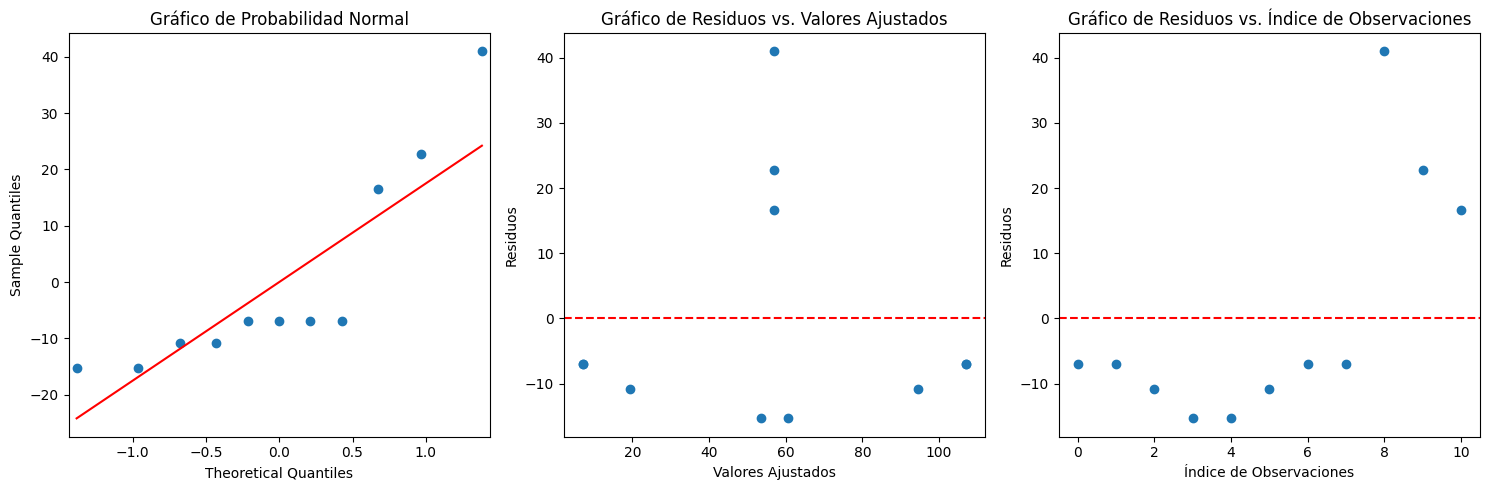

In [27]:
import matplotlib.pyplot as plt

# Se obtienen los residuos del modelo
residuos = modelo.resid
valores_ajustados = modelo.fittedvalues

# Crear una figura con tres subplots en una fila
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Gráfico de probabilidad normal (QQ-plot)
sm.qqplot(residuos, line='s', ax=axs[0])
axs[0].set_title('Gráfico de Probabilidad Normal')

# Gráfico de residuos vs. valores ajustados
axs[1].scatter(valores_ajustados, residuos)
axs[1].set_xlabel('Valores Ajustados')
axs[1].set_ylabel('Residuos')
axs[1].set_title('Gráfico de Residuos vs. Valores Ajustados')
# Agregar una línea punteada en el eje y en 0
axs[1].axhline(0, color='red', linestyle='--')

# Gráfico de dispersión de residuos vs. índice de observaciones
indice_observaciones = pd.Series(range(len(residuos)))
axs[2].scatter(indice_observaciones, residuos)
axs[2].set_xlabel('Índice de Observaciones')
axs[2].set_ylabel('Residuos')
axs[2].set_title('Gráfico de Residuos vs. Índice de Observaciones')
# Agregar una línea punteada en el eje y en 0
axs[2].axhline(0, color='red', linestyle='--')

# Ajustar la disposición de los subplots para evitar superposiciones
plt.tight_layout()

# Mostrar los gráficos
plt.show()

#####  Galactosa

In [28]:
#modelo = ols('Ƞgalac ~ A - B + C + D - A:B + A:C + A:D', data=design).fit()
modelo = ols('Ƞgalac ~  B - A + C + D - A:B - A:C - A:D - B:C - B:D + C:D', data=design).fit()

In [29]:
Ajuste_ANOVA (design, var_name='Ƞgalac')
Analizar_Curvatura_y_faltaDeAjuste (design, factors, modelo, var_name='Ƞgalac')

Estadístico,Valor
R2 =,97.85%
RADJ2 =,96.42%
Valor-p del modelo =,3.90719e-05
GL del modelo =,4.0


           df       sum_sq      mean_sq           F    PR(>F)
B         1.0     9.245000     9.245000    1.386340  0.283609
C         1.0   403.280000   403.280000   60.474133  0.000238
D         1.0  1058.000000  1058.000000  158.653125  0.000015
C:D       1.0   351.125000   351.125000   52.653193  0.000348
Residual  6.0    40.011818     6.668636         NaN       NaN



Efecto menos significativo:,B
Valor p:,0.283609



Intercept    12.027273
B             1.075000
C             7.100000
D            11.500000
C:D           6.625000
dtype: float64

Ecuación del modelo:
Ƞgalac=  12.0273 * Intercept + 1.0750 * B + 7.1000 * C + 11.5000 * D + 6.6250 * C:D
Error Puro: 2, df_lack_of_fit: 4.0, MS_error_puro: 18.013333333333332, p_value_lack_of_fit: 0.9900799673292441
Central Data not empty

--- Falta de ajuste ---
Suma de Cuadrados de Falta de Ajuste: 3.9851515151515002
Grados de libertad de Falta de Ajuste: 4.0
F-valor para Falta de Ajuste: 0.05530835744566294
 p-valor para Falta de Ajuste: 0.9900799673292441 

--- Curvatura (solo si hay puntos centrales) ---
Suma de Cuadrados de Curvatura: 0.08015151515151347
F-valor para Curvatura: 0.012019176152500153
 p-valor para Curvatura: 0.9162760749991442 


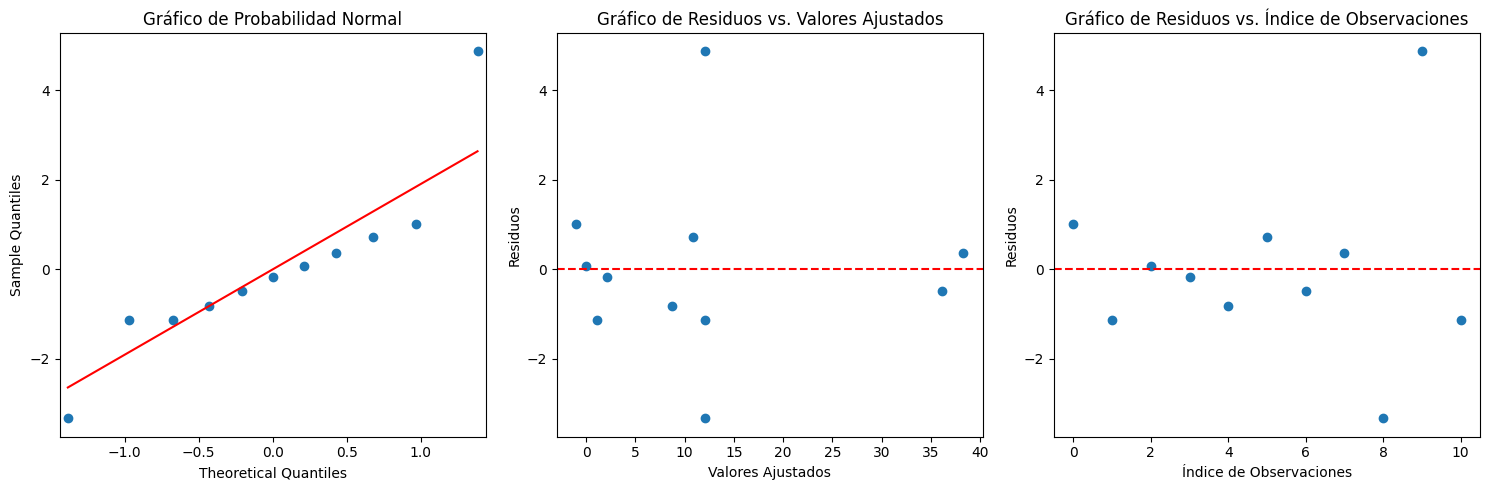

In [30]:
import matplotlib.pyplot as plt

# Se obtienen los residuos del modelo
residuos = modelo.resid
valores_ajustados = modelo.fittedvalues

# Crear una figura con tres subplots en una fila
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Gráfico de probabilidad normal (QQ-plot)
sm.qqplot(residuos, line='s', ax=axs[0])
axs[0].set_title('Gráfico de Probabilidad Normal')

# Gráfico de residuos vs. valores ajustados
axs[1].scatter(valores_ajustados, residuos)
axs[1].set_xlabel('Valores Ajustados')
axs[1].set_ylabel('Residuos')
axs[1].set_title('Gráfico de Residuos vs. Valores Ajustados')
# Agregar una línea punteada en el eje y en 0
axs[1].axhline(0, color='red', linestyle='--')

# Gráfico de dispersión de residuos vs. índice de observaciones
indice_observaciones = pd.Series(range(len(residuos)))
axs[2].scatter(indice_observaciones, residuos)
axs[2].set_xlabel('Índice de Observaciones')
axs[2].set_ylabel('Residuos')
axs[2].set_title('Gráfico de Residuos vs. Índice de Observaciones')
# Agregar una línea punteada en el eje y en 0
axs[2].axhline(0, color='red', linestyle='--')

# Ajustar la disposición de los subplots para evitar superposiciones
plt.tight_layout()

# Mostrar los gráficos
plt.show()

#####  Hemicelulosa

res = ['ȠXyl', 'Ƞarab', 'Ƞman', 'Ƞhemi', 'Ƞgalac']

In [31]:
#modelo = ols('Ƞman ~ A - B + C + D - A:B + A:C + A:D', data=design).fit()
modelo = ols('Ƞhemi ~ B - A +C + D - A:B - A:C - A:D - B:C - B:D + C:D', data=design).fit()

In [32]:
Ajuste_ANOVA(design, var_name='Ƞhemi')
Analizar_Curvatura_y_faltaDeAjuste(design, factors, modelo, var_name='Ƞhemi')

Estadístico,Valor
R2 =,90.19%
RADJ2 =,83.65%
Valor-p del modelo =,0.00349905
GL del modelo =,4.0


           df      sum_sq    mean_sq          F    PR(>F)
B         1.0   55.125000   55.12500   2.609533  0.157350
C         1.0  271.445000  271.44500  12.849790  0.011578
D         1.0  748.845000  748.84500  35.449174  0.001004
C:D       1.0   89.780000   89.78000   4.250048  0.084872
Residual  6.0  126.746818   21.12447        NaN       NaN



Efecto menos significativo:,B
Valor p:,0.15735



Intercept    15.372727
B             2.625000
C             5.825000
D             9.675000
C:D           3.350000
dtype: float64

Ecuación del modelo:
Ƞhemi=  15.3727 * Intercept + 2.6250 * B + 5.8250 * C + 9.6750 * D + 3.3500 * C:D
Error Puro: 2, df_lack_of_fit: 4.0, MS_error_puro: 2.093333333333338, p_value_lack_of_fit: 0.06497236466254341
Central Data not empty

--- Falta de ajuste ---
Suma de Cuadrados de Falta de Ajuste: 122.56015151515155
Grados de libertad de Falta de Ajuste: 4.0
F-valor para Falta de Ajuste: 14.636960770121568
 p-valor para Falta de Ajuste: 0.06497236466254341 

--- Curvatura (solo si hay puntos centrales) ---
Suma de Cuadrados de Curvatura: 102.87515151515163
F-valor para Curvatura: 4.869951908421588
 p-valor para Curvatura: 0.06944896747679707 


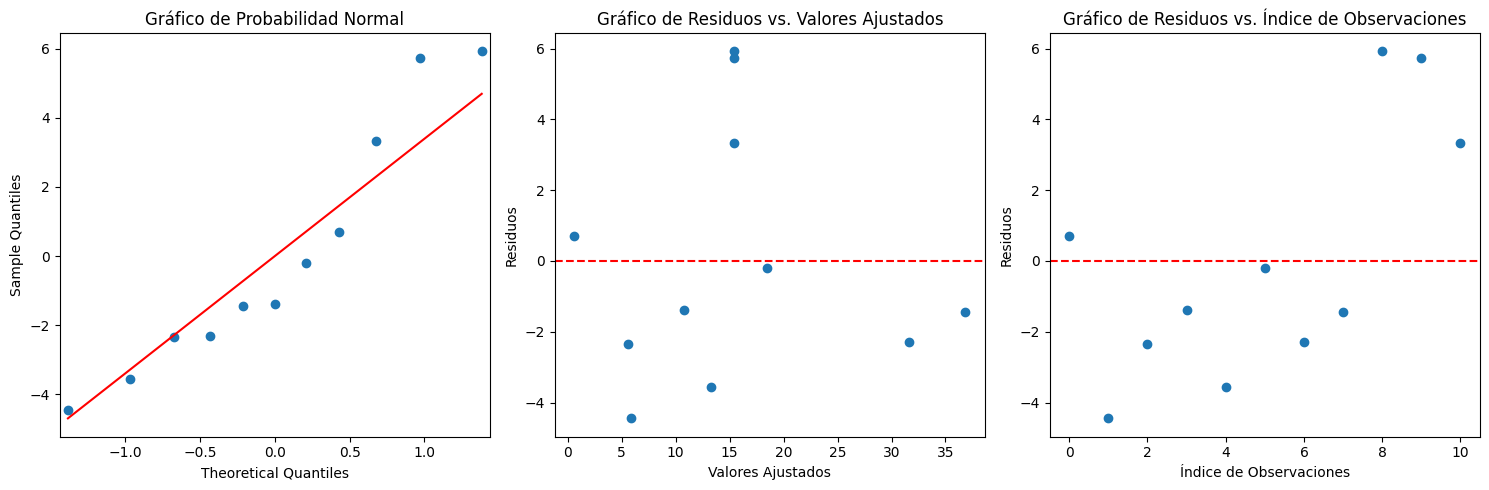

In [33]:
import matplotlib.pyplot as plt

# Se obtienen los residuos del modelo
residuos = modelo.resid
valores_ajustados = modelo.fittedvalues

# Crear una figura con tres subplots en una fila
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Gráfico de probabilidad normal (QQ-plot)
sm.qqplot(residuos, line='s', ax=axs[0])
axs[0].set_title('Gráfico de Probabilidad Normal')

# Gráfico de residuos vs. valores ajustados
axs[1].scatter(valores_ajustados, residuos)
axs[1].set_xlabel('Valores Ajustados')
axs[1].set_ylabel('Residuos')
axs[1].set_title('Gráfico de Residuos vs. Valores Ajustados')
# Agregar una línea punteada en el eje y en 0
axs[1].axhline(0, color='red', linestyle='--')

# Gráfico de dispersión de residuos vs. índice de observaciones
indice_observaciones = pd.Series(range(len(residuos)))
axs[2].scatter(indice_observaciones, residuos)
axs[2].set_xlabel('Índice de Observaciones')
axs[2].set_ylabel('Residuos')
axs[2].set_title('Gráfico de Residuos vs. Índice de Observaciones')
# Agregar una línea punteada en el eje y en 0
axs[2].axhline(0, color='red', linestyle='--')

# Ajustar la disposición de los subplots para evitar superposiciones
plt.tight_layout()

# Mostrar los gráficos
plt.show()

##### Manosa

In [40]:
#modelo = ols('Ƞman ~ A - B + C + D - A:B + A:C + A:D', data=design).fit()
# modelo = ols('Ƞman ~  A + B + C + D - A:B - A:C - A:D - B:C - B:D - C:D', data=design).fit()
modelo = ols('Ƞman ~  A + B + C + D - A:B - A:C - A:D - B:C - B:D - C:D - A', data=design).fit()

In [41]:
Ajuste_ANOVA(design, var_name='Ƞman')
Analizar_Curvatura_y_faltaDeAjuste(design, factors, modelo, var_name='Ƞman')

Estadístico,Valor
R2 =,17.82%
RADJ2 =,-17.40%
Valor-p del modelo =,0.69039
GL del modelo =,3.0


           df      sum_sq    mean_sq         F    PR(>F)
B         1.0   19.845000  19.845000  0.504612  0.500455
C         1.0   22.445000  22.445000  0.570724  0.474619
D         1.0   17.405000  17.405000  0.442569  0.527189
Residual  7.0  275.290455  39.327208       NaN       NaN



Efecto menos significativo:,D
Valor p:,0.527189



Intercept    12.663636
B             1.575000
C             1.675000
D             1.475000
dtype: float64

Ecuación del modelo:
Ƞman=  12.6636 * Intercept + 1.5750 * B + 1.6750 * C + 1.4750 * D
Error Puro: 2, df_lack_of_fit: 5.0, MS_error_puro: 1.9733333333333332, p_value_lack_of_fit: 0.035456483469626376
Central Data not empty

--- Falta de ajuste ---
Suma de Cuadrados de Falta de Ajuste: 271.3437878787879
Grados de libertad de Falta de Ajuste: 5.0
F-valor para Falta de Ajuste: 27.501059582309587
 p-valor para Falta de Ajuste: 0.035456483469626376 

--- Curvatura (solo si hay puntos centrales) ---
Suma de Cuadrados de Curvatura: 244.76378787878772
F-valor para Curvatura: 6.223777420762749
 p-valor para Curvatura: 0.041308368630579295 


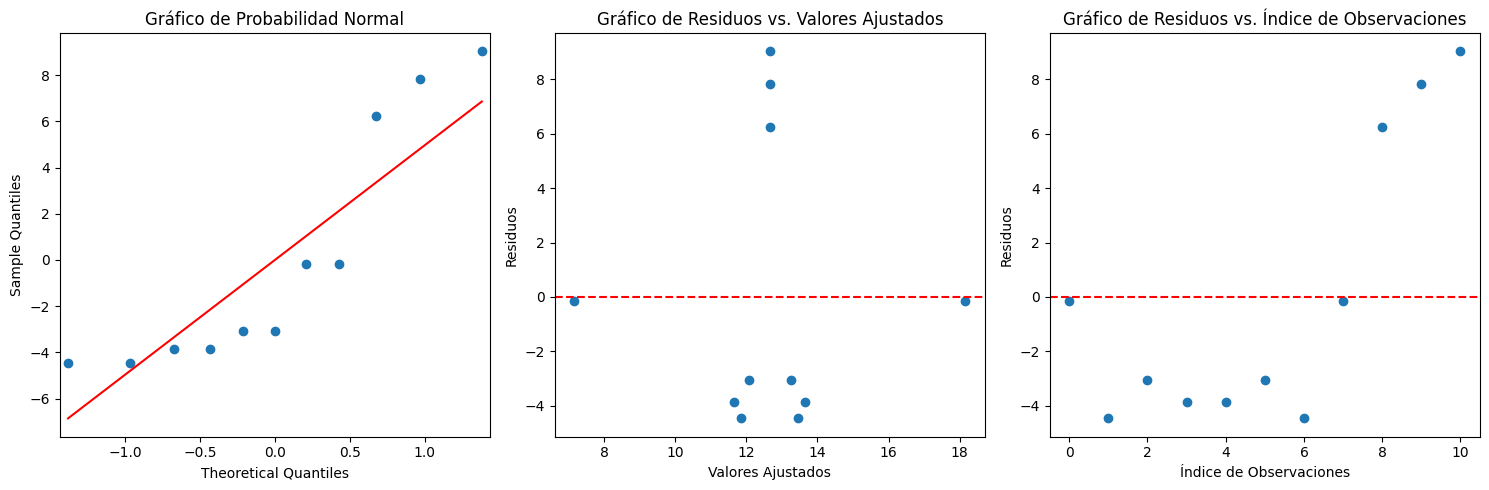

In [39]:
import matplotlib.pyplot as plt

# Se obtienen los residuos del modelo
residuos = modelo.resid
valores_ajustados = modelo.fittedvalues

# Crear una figura con tres subplots en una fila
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Gráfico de probabilidad normal (QQ-plot)
sm.qqplot(residuos, line='s', ax=axs[0])
axs[0].set_title('Gráfico de Probabilidad Normal')

# Gráfico de residuos vs. valores ajustados
axs[1].scatter(valores_ajustados, residuos)
axs[1].set_xlabel('Valores Ajustados')
axs[1].set_ylabel('Residuos')
axs[1].set_title('Gráfico de Residuos vs. Valores Ajustados')
# Agregar una línea punteada en el eje y en 0
axs[1].axhline(0, color='red', linestyle='--')

# Gráfico de dispersión de residuos vs. índice de observaciones
indice_observaciones = pd.Series(range(len(residuos)))
axs[2].scatter(indice_observaciones, residuos)
axs[2].set_xlabel('Índice de Observaciones')
axs[2].set_ylabel('Residuos')
axs[2].set_title('Gráfico de Residuos vs. Índice de Observaciones')
# Agregar una línea punteada en el eje y en 0
axs[2].axhline(0, color='red', linestyle='--')

# Ajustar la disposición de los subplots para evitar superposiciones
plt.tight_layout()

# Mostrar los gráficos
plt.show()

#####  Xilosa

res = ['ȠXyl', 'Ƞarab', 'Ƞman', 'Ƞhemi', 'Ƞgalac']

In [34]:
#modelo = ols('ȠXyl ~ A - B + C + D - A:B + A:C + A:D', data=design).fit()
modelo = ols('ȠXyl ~  A + B + C + D + A:B + A:C + A:D - B:C - B:D - C:D', data=design).fit()

In [35]:
Ajuste_ANOVA(design, var_name='ȠXyl')
Analizar_Curvatura_y_faltaDeAjuste(design, factors, modelo, var_name='ȠXyl')

Estadístico,Valor
R2 =,93.52%
RADJ2 =,78.42%
Valor-p del modelo =,0.0811177
GL del modelo =,7.0


           df     sum_sq    mean_sq          F    PR(>F)
A         1.0  11.045000  11.045000   2.582527  0.206408
B         1.0  11.045000  11.045000   2.582527  0.206408
C         1.0  11.045000  11.045000   2.582527  0.206408
D         1.0  11.045000  11.045000   2.582527  0.206408
A:B       1.0  47.045000  47.045000  11.000000  0.045168
A:C       1.0  47.045000  47.045000  11.000000  0.045168
A:D       1.0  47.045000  47.045000  11.000000  0.045168
Residual  3.0  12.830455   4.276818        NaN       NaN



Efecto menos significativo:,C
Valor p:,0.206408



Intercept    1.763636
A            1.175000
B            1.175000
C            1.175000
D            1.175000
A:B          2.425000
A:C          2.425000
A:D          2.425000
dtype: float64

Ecuación del modelo:
ȠXyl=  1.7636 * Intercept + 1.1750 * A + 1.1750 * B + 1.1750 * C + 1.1750 * D + 2.4250 * A:B + 2.4250 * A:C + 2.4250 * A:D
Error Puro: 2, df_lack_of_fit: 1.0, MS_error_puro: 0.0, p_value_lack_of_fit: nan
Central Data not empty

--- Falta de ajuste ---
Suma de Cuadrados de Falta de Ajuste: 12.830454545454549
Grados de libertad de Falta de Ajuste: 1.0
F-valor para Falta de Ajuste: nan
 p-valor para Falta de Ajuste: nan 

--- Curvatura (solo si hay puntos centrales) ---
Suma de Cuadrados de Curvatura: 12.830454545454545
F-valor para Curvatura: 2.999999999999999
 p-valor para Curvatura: 0.18169011381620914 


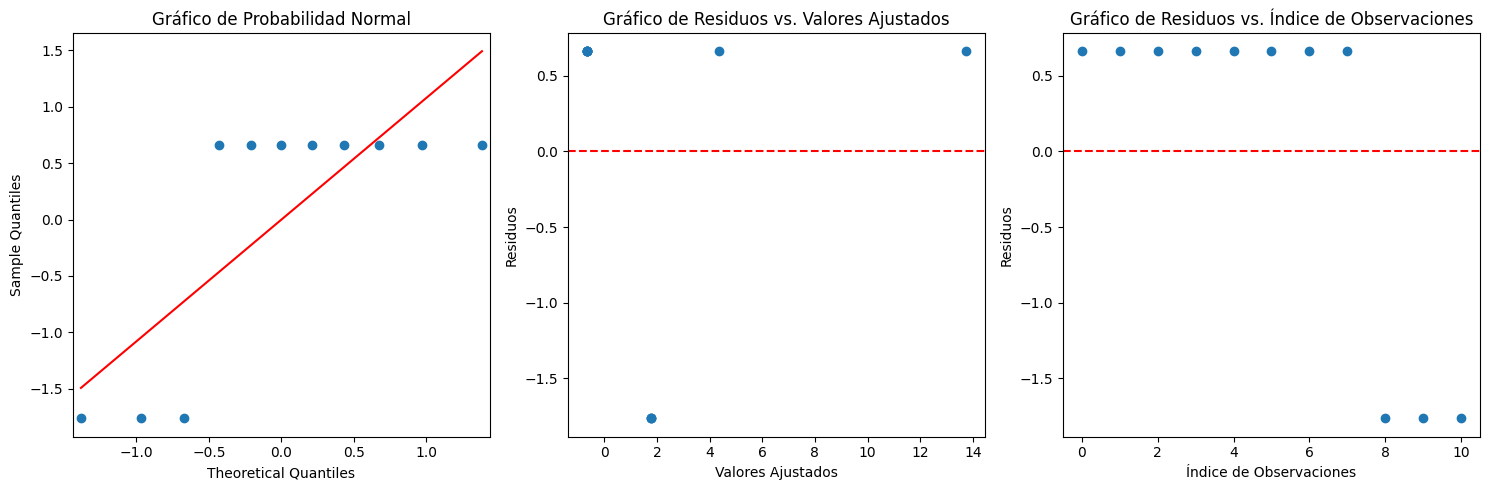

In [36]:
import matplotlib.pyplot as plt

# Se obtienen los residuos del modelo
residuos = modelo.resid
valores_ajustados = modelo.fittedvalues

# Crear una figura con tres subplots en una fila
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Gráfico de probabilidad normal (QQ-plot)
sm.qqplot(residuos, line='s', ax=axs[0])
axs[0].set_title('Gráfico de Probabilidad Normal')

# Gráfico de residuos vs. valores ajustados
axs[1].scatter(valores_ajustados, residuos)
axs[1].set_xlabel('Valores Ajustados')
axs[1].set_ylabel('Residuos')
axs[1].set_title('Gráfico de Residuos vs. Valores Ajustados')
# Agregar una línea punteada en el eje y en 0
axs[1].axhline(0, color='red', linestyle='--')

# Gráfico de dispersión de residuos vs. índice de observaciones
indice_observaciones = pd.Series(range(len(residuos)))
axs[2].scatter(indice_observaciones, residuos)
axs[2].set_xlabel('Índice de Observaciones')
axs[2].set_ylabel('Residuos')
axs[2].set_title('Gráfico de Residuos vs. Índice de Observaciones')
# Agregar una línea punteada en el eje y en 0
axs[2].axhline(0, color='red', linestyle='--')

# Ajustar la disposición de los subplots para evitar superposiciones
plt.tight_layout()

# Mostrar los gráficos
plt.show()